# Statistical Techniques for Data Analysis
# Countinuous Assessment 1

## Task 1) Calculate the expected value for the club for both games. 
## Task 2) Create simulations of each game in Python. 
## Task 3) Calculate the measures of central tendency for each game, based off an appropriate number of simulations.
## Task 4) Calculate the measures of dispersion for each game, based off an appropriate number of simulations. 

## Assessment Details:
### A local GAA club is designing a new game to be a fundraiser for the club. They have seen 2 proposals:A local GAA club is designing a new game to be a fundraiser for the club. They have seen 2 proposals:

### Task 1.1) Calculate the expected value for the club for game 1.

## Game 1

### The player pays €5 and picks 3 letters (all lower case English letters) and 2 digits (numbers 0-9 inclusive). They win as follows:
  #### What is correct         	Prize
#### 3 letters, both numbers	     €100
#### Two letters, both numbers  	€50
#### One letter, both numbers	€25
#### No letter, both numbers	     €10


In [1]:
# The probability of getting 3 letters and 2 numbers correct.
PLLLnn = 1/26 * 1/26 * 1/26 * 1/10 * 1/10
PLLLnn

5.689576695493856e-07

In [2]:
# The probability of getting 2 letters and 2 numbers correct. The position of where the correct letter is located does not matter.
PLLnn = ((1/26 * 1/26 * 25/26 * 1/10 * 1/10)+(1/26 * 25/26 * 1/26 * 1/10 * 1/10)+(25/26 * 1/26 * 1/26 * 1/10 * 1/10))
PLLnn

4.267182521620391e-05

In [3]:
# The probability of getting 1 letter and 2 numbers correct. Independentely of the position of the right letter.
PLnn = ((1/26 * 25/26 * 25/26 * 1/10 * 1/10)+(25/26 * 1/26 * 25/26 * 1/10 * 1/10)+(25/26 * 25/26 * 1/26 * 1/10 * 1/10))
PLnn 

0.001066795630405098

In [4]:
# The probability of getting the 2 numbers correct. The letters do not matter.
Pnn = 25/26 * 25/26 * 25/26 * 1/10 * 1/10
Pnn

0.00888996358670915

#### Expected value 
##### Probability of the outcome, times the actual outcome 
$E[x] = ΣP(xi) . xi$               


In [5]:
# Expected value with math formula
# https://campus.datacamp.com/courses/foundations-of-probability-in-python/lets-start-flipping-coins?ex=8
# The probability of getting 3 letters and 2 numbers correct, times the prize of getting 3 letters and 2 numbers correct.
# Plus, the probability of getting 2 letters and 2 numbers correct, times the prize of getting 2 letters and 2 numbers correct.
# Plus, the probability of getting 1 letter and 2 numbers correct, times the prize of getting 1 letter and 2 numbers correct.
# Plus, the probability of getting 2 numbers correct, times the prize for getting 2 numbers correct.

Exp_value1 = PLLLnn*100 + PLLnn*50 + PLnn*25 + Pnn*10
print (Exp_value1)

0.1177600136549841


### The profit the club expects for every ticket sold to every player is €4.88
##### Profit = revenue – expense
###### In this case 
###### Profit = 5 - 0.12
###### Profit = 4.88


In [6]:
# Expected value with python code
# Over many plays, players will win on average €0.12 per play. Organisers need to charge €0.12 not to lose money. (Break even)

win_data = [
    [100, PLLLnn],
    [50, PLLnn],
    [25, PLnn],
    [10, Pnn]
]

expected_value = 0
for wins in win_data:
    expected_value += wins[0] * wins[1]
    print(f"Ex: {wins[0] * wins[1]}")
print(expected_value)
print(expected_value -5)

Ex: 5.689576695493856e-05
Ex: 0.0021335912608101953
Ex: 0.026669890760127452
Ex: 0.08889963586709151
0.1177600136549841
-4.882239986345016


#### The expected value is a number to represent the average outcome of the game.
#### Over many plays, the buyers of tickets win on average €0.117.
#### €0.117 is the ideal ticket prize the organisers should charge per ticket in order to break even.
#### After spending €5 for each game, players are losing on average €4.88 per game. 
#### Organisers have an average profit of $4.88 per game/player.

### Task 2.1) Create simulation of game 1 in Python. 

# Game 1 simulator

In [7]:
import random
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [8]:
# This is the simulation of every play make by the people who buy a ticket.
# Vs the results of every time the organisers draw the winning combinations.
# Visual example of what letters and numbers the players are able to pick

#Every player picks their 3 letters and 2 numbers
def letter():
    outcomes = ["a", "b", "c", "d", "e", "f", "g", "h", "i", "j", "k", "l", "m", "n", "o", "p", "q", "r", "s", "t", "u", "v", "w", "x", "y", "z"]
    return outcomes[random.randint(0, 25)]
def number():
    return str(random.randint(0, 9))
def play():
    return letter()+letter()+letter()+number()+number()

# Organisers draw results
def w_letter():
    outcomes = ["a", "b", "c", "d", "e", "f", "g", "h", "i", "j", "k", "l", "m", "n", "o", "p", "q", "r", "s", "t", "u", "v", "w", "x", "y", "z"]
    return outcomes[random.randint(0, 25)]
def w_number():
    return str(random.randint(0, 9))
def game():
    return w_letter()+w_letter()+w_letter()+w_number()+w_number()  

    

In [9]:
#The visual results of every game and every draw.
# The outcomes show in some extent how likely is for a match to happen. Or how far are the distances between every draw.
print(play())
print (game())
    

uju91
twu75


In [10]:
# This is the results of the combinations
# There will be 3 winner letters and 2 winner numbers


def raffle_matches():
    winner_letters = [letter(), letter(), letter()]
    winner_numbers = [number(), number()]

# Players will have picked 3 letters and 2 numbers
    players_letters = [letter(), letter(), letter()]
    players_numbers = [number(), number()]

# The matches are created by comparing each position of player's guess with the position of the winning combination. 
# If the respective values and their positions are identical, there is a 'MATCH'.

    letters_match = sum([1 for i in range(3) if players_letters[i] == winner_letters[i]])
    numbers_match = sum([1 for i in range(2) if players_numbers[i] == winner_numbers[i]])

# These are the conditions for each match 

    if letters_match == 3 and numbers_match == 2:
        return "LLLnn"
    elif letters_match == 2 and numbers_match == 2:
        return "LLnn"
    elif letters_match == 1 and numbers_match == 2:
        return "Lnn"
    elif numbers_match == 2:
        return "nn"
    else:
        return "0"

In [11]:
# Outcome of last code.
# This responds to the questions: 
#'Is there a match?'
# What type of match is it?

raffle_matches()

'0'

In [12]:
# The respective prizes for each type of match, or 0 if there is not any match.
def raffle_prizes():
    Matches = raffle_matches()
    outcome = [Matches]
    if outcome == ["LLLnn"]:
        prize = 100
    elif outcome == ["LLnn"]:
        prize = 50
    elif outcome == ["Lnn"]:
        prize = 25
    elif outcome == ["nn"]:
        prize = 10
    
    else:
        prize = 0
    
    return outcome, prize

In [13]:
# Outcomes of the last code.
# On the first outcome it is shown the type of match it was got, or outcome of 0 if there was not a match.
# On the second outcome it is shown the prize won by obtaining a match, or 0 if there was not match obtained.
raffle_prizes()

(['0'], 0)

### Task 3.1) Calculate the measures of central tendency for game 1, based off an appropriate number of simulations.

In [14]:
# Calculate the mean of the results of the prizes
# On average prizes, over 100000 plays of the game are $0.11, 
#Shows a similar result to the expected value.
results = pd.DataFrame({
    "Matches": [], 
    "Prize": []
})
#results
num_plays = 1000000
for i in range (num_plays):
    outcome, prize = raffle_prizes()
    new_result = pd.DataFrame({
        "Matches": [outcome [0]],
        "Prize": [prize]
})
    results = pd.concat ([results, new_result])
results["Prize"].mean()

np.float64(0.11905)

In [15]:
#Cumulative probability or acumulation of probabilities 

def LOTTO():
    win_data = [
        [100, PLLLnn],
        [50, PLLnn],
        [25, PLnn],
        [10, PLnn]
    ]    
    random_num = random.random()
    cumulative_propability = 0
    for wins in win_data:
        cumulative_propability += wins[1]
        if cumulative_propability >= random_num:
            return wins[0]
    return 0

In [16]:
# Visual example of the prizes won in 100_000 plays
for i in range(100000):
   print(LOTTO())

0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
25
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
10
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0


In [17]:
# Central tendency

print("Mean:", results["Prize"].mean())
print("Median:", results["Prize"].median())
print("Mode:", results["Prize"].mode()[0])

Mean: 0.11905
Median: 0.0
Mode: 0.0


#### Results:
#### Over 100.000 plays the average value of the Prizes is 0.11905. With that it is shown that the mean of the Game 1 is very close to the Expected Value.
#### The median represents the middle value of an ordered dataset. In Game 1, after putting all the obtained prizes in an ordinal line from the lowest to the biggest number, the division of the 2 middle numbers is 0. By this, it is recongnized that most of the results are 0 and all the prizes are in the 75% quartile.
#### The mode is the most frequent value in a dataset. In game 1 the number which appears the most is 0. 

### Task 4.1) Calculate the measures of dispersion for game 1, based off an appropriate number of simulations. 

In [18]:
#Variacion: same as we get when we use function 'describe'
print("Variance:", results["Prize"].var())
print("Standard Deviation:", results["Prize"].std(ddof=0))
print("Min:", results ["Prize"].min())
print("Max:", results ["Prize"].max())

Variance: 1.67507877258788
Standard Deviation: 1.2942476955780557
Min: 0.0
Max: 50.0


#### Results:
#### The average of the squared deviations from the mean for Game 1 is 1.67. This represents a low variance for Game1.
#### The standard deviation for Game 1 is 1.29. This represents the distance of each value from the mean in the same units(€). This shows small standard deviation.
#### Range is the difference between the highest and lowest values. For game 1 the highest prize is €100. However in the simulator the highest prize obtained was €50 and the lowest 0. For this case 50-0= 50. Concluding with a range of 50.

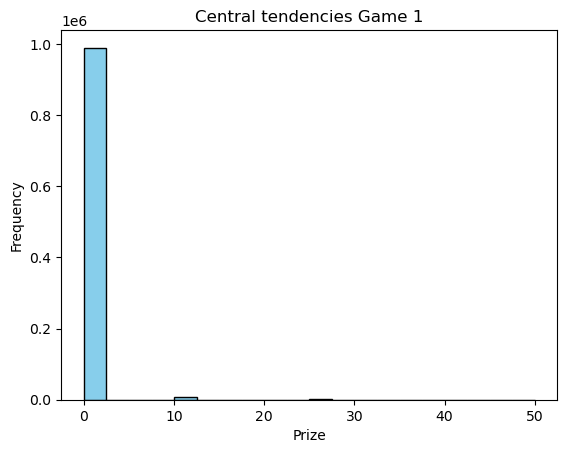

In [19]:

# Histogram of central tendencies of Game 1
plt.hist(results["Prize"], bins=20, color='skyblue', edgecolor='black')

# Adding labels and title
plt.xlabel('Prize')
plt.ylabel('Frequency')
plt.title('Central tendencies Game 1')

# Display the plot
plt.show()

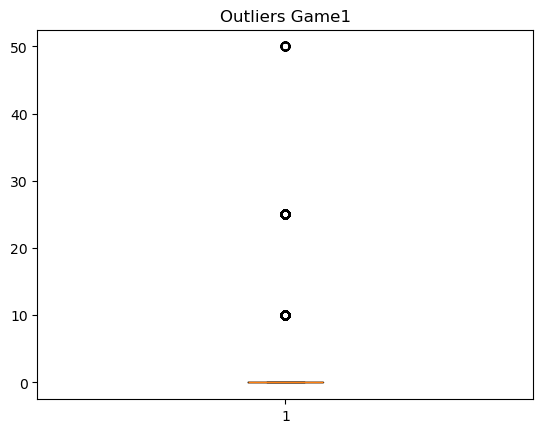

In [20]:
# Boxplot to recognize outliers for Game 1.
plt.boxplot(results["Prize"]) 
plt.title('Outliers Game1') 
plt.show()

#### Skewness:
#### When the value of the mean is higher than the value of the median and the mode, we encounter a right-skewed distribution.
#### In game 1: The mean = 0.1195, the median and mode are lower than the mean (0).
#### There is a high concentration of low values. Almost a 100% of the results are 0. 
#### On the other hand, the prizes such as 10, 25, 50 and 100 happen rarely. 
#### Conclusion: Game 1 is right skewed, beause most of outcomes are zero, while a few of the higher values appear on the right hand side of the distribution.


### Task 1.2) Calculate the expected value for the club for game 2.

# Game 2


### The player pays €5 and picks 3 letters (all lower case AND upper case English letters, repetition allowed). 
#### If they guess all correctly, they win €500,000


In [21]:
# The probability of picking the three correct letter, considering all lower and upper cases and repetitions allowed
# There are 26 letters in the alphabet, this multiplied by 2, equals 52, one of them is the winner letter for that position.
# Then 1 of the winning letters out of 52 posibilities.
PLLL = 1/52 * 1/52 * 1/52

In [22]:
PLLL

7.11197086936732e-06

In [23]:
1/140608

7.111970869367319e-06

#### Expected value 
##### Probability of the outcome, times the actual outcome 
$E[x] = ΣP(xi) . xi$               


In [24]:
# Expected value with math formula
Exp_value2 = PLLL*500000
print (Exp_value2)

3.55598543468366


### The profit the club expects for every ticket sold to every player is €1.44.
##### Profit = revenue – expense
###### In this case 
###### Profit = 5 - 3.55
###### Profit = 1.44


In [25]:
# Expected value with python code
# Over many plays, players will win on average €3.55 per play. Organisers need to charge €3.55 not to lose money.

win_data = [
    [500000, PLLL],
]

expected_value = 0
for wins in win_data:
    expected_value += wins[0] * wins[1]
    print(f"Ex: {wins[0] * wins[1]}")
print(expected_value)
print(expected_value -5)

Ex: 3.55598543468366
3.55598543468366
-1.44401456531634


#### The expected value is a number to represent the average outcome of the game.
#### Over many plays, the buyers of tickets win on average €3.555.
#### €3.555 is the ideal ticket prize the organisers should charge per ticket in order to break even.
#### After spending €5 for each game, players are losing on average €1.44 per game. 
#### Organisers have an average profit of €1.44 per game/player.

### Task 2.2) Create simulation of game 2 in Python. 

## Game 2 simulator

In [26]:

from string import ascii_letters
import string


In [27]:
# This is the simulation of every play make by the people who buy a ticket. 
# Comparing to the results of every time the organisers draw the winning combinations.


#Every player picks their 3 letters: upper and/or lower case
def letter2():
    return random.choice(string.ascii_letters)
    
# Organisers draw results
def w_letter2():
    return random.choice(string.ascii_letters)
    
# Outcome of every play    
def play2():
    return letter2()+letter2()+letter2()
    
# Outcome of every draw
def game2():
    return w_letter2()+w_letter2()+w_letter2()  

    

In [28]:
#The visual results of every game and every draw in Game2.
# The outcomes show in some extent how likely is for a match to happen. Or how far are the distances between every draw.
print(play2())
print (game2())
    

EDQ
bOm


In [29]:
# This is the results of the combinations
# There will be 3 winner letters (out of 52 posibilities)
# Players will have picked 3 letters

def raffle_matches2():
    winner_letters2 = [letter2(), letter2(), letter2()]
    
    players_letters2 = [letter2(), letter2(), letter2()]
   
# The matches are created by comparing each position of player's guess with the position of the winning combination of 3 letters. 
# If the respective values and their positions are identical, there is a MATCH.

    letters_match2 = sum([1 for i in range(3) if players_letters2[i] == winner_letters2[i]])


# This is the condition for the match. 

    if letters_match2 == 3:
        return "Winner"
    else:
        return "0"

In [30]:
# Outcome of last code.
# This answers to the question: 
#'Is there a match?'

raffle_matches2()

'0'

In [31]:
# There is only 1 possibility for a match 
# The condition is to have picked the correct 3 letters upper/lower case in the correct position.
# If the condition is reached, the prize is €500.000
# If not, there is no prize.
def raffle_prizes2():
    Matches2 = raffle_matches2()
    outcome = [Matches2]
    if outcome == ["Winner"]:
        prize2 = 500000
    
    else:
        prize2 = 0
    
    return outcome, prize2

In [32]:
# Outcomes of the last code.
# On the first outcome it is shown the match, or outcome of 0 if there was not a match.
# On the second outcome it is shown the prize won by guessing the right combination, or 0 if there was not match obtained.
raffle_prizes2()

(['0'], 0)

### Task 3.2) Calculate the measures of central tendency for game 2, based off an appropriate number of simulations.

In [26]:
# Calculate the mean of the results of the prizes
# on average prizes are $
results2 = pd.DataFrame({
    "Matches2": [], 
    "Prize2": []
})
#results
num_plays2 = 1000000
for i in range (num_plays2):
    outcome, prize2 = raffle_prizes2()
    
    new_result2 = pd.DataFrame({
        "Matches2": [outcome[0]],
        "Prize2": [prize2]
})
    results2 = pd.concat ([results2, new_result2])
results2["Prize2"].mean()

np.float64(3.0)

In [34]:
#Cumulative probability or acumulation of probabilities 

def LOTTO2():
    win_data2 = [
        [500000, PLLL],
    ]    
    random_num = random.random()
    cumulative_propability = 0
    for wins in win_data2:
        cumulative_propability += wins[1]
        if cumulative_propability >= random_num:
            return wins[0]
    return 0

In [35]:
# Visual example of the prizes won in 100_000 plays
for i in range(100000):
    print(LOTTO2())

0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0


In [28]:
# Central tendency
print("Mean:", results2["Prize2"].mean())
print("Median:", results2["Prize2"].median())
print("Mode:", results2["Prize2"].mode()[0])

Mean: 3.0
Median: 0.0
Mode: 0.0


#### Results:
#### Over 100.000 plays the average value of the Prizes is 3. With that it is shown that the mean of the Game 2 is to certain extent, not too far away from the Expected Value.
#### The median represents the middle value of an ordered dataset. In Game 2, after organizing all the outcomes of the obtained prizes in an ordinal line from the lowest to the biggest number, the division of the 2 middle numbers is 0. By this, it is recongnized that most of the results are 0 and all the prizes are in the 75% quartile.
#### The mode is the most frequent value in a dataset. In game 2 the number which appears the most is 0.

### Task 4.2) Calculate the measures of dispersion for game 2, based off an appropriate number of simulations. 

In [29]:
#Variacion: same as we get when we use function 'describe'
print("Variance:", results2["Prize2"].var())
print("Standard Deviation:", results2["Prize2"].std(ddof=0))
print("Min:", results2 ["Prize2"].min())
print("Max:", results2 ["Prize2"].max())

Variance: 1499992.4999925
Standard Deviation: 1224.7411971514634
Min: 0.0
Max: 500000.0


#### Results:
#### The average of the squared deviations from the mean for Game 2 is 1499992. This represents a very high variance for Game 2, meaning the values are spread out.
#### The standard deviation for Game 1 is 1224. This represents the distance of each value from the mean in the same units(€). This shows a large distance from each value to the mean. There is a distance of €1581, this represents unpredictable payouts for Game2.
#### Range is the difference between the highest and lowest values. For game 2 the highest prize is €500000. Even though in the simulator this prize was obtained only once. For this case 500000-0= 500000. Concluding with a range of 500000.

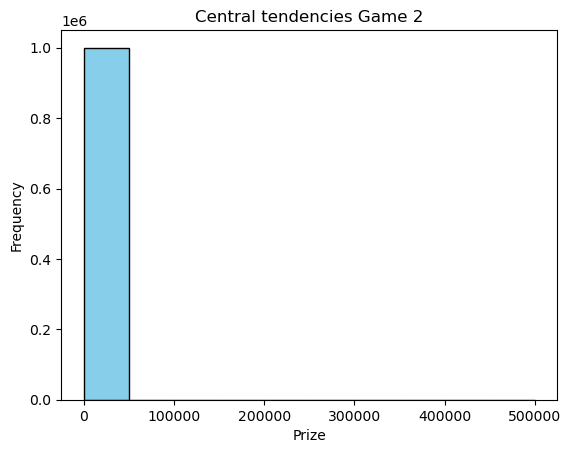

In [30]:
# Histogram of central tendencies of Game 2
plt.hist(results2["Prize2"], bins=10, color='skyblue', edgecolor='black')

# Adding labels and title
plt.xlabel('Prize')
plt.ylabel('Frequency')
plt.title('Central tendencies Game 2')

# Display the plot
plt.show()

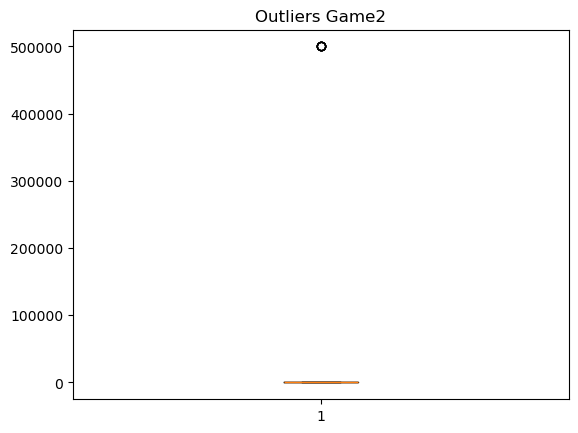

In [31]:
# Boxplot to recognize outliers for Game 2
plt.boxplot(results2["Prize2"]) 
plt.title('Outliers Game2') 
plt.show()

#### Skewness:
#### When the value of the mean is higher than the value of the median and the mode, we encounter a right-skewed distribution.
#### In game 2: The mean = 3, the median and mode are lower than the mean (0).
#### There is a high concentration of low values. Almost a 100% of the results are 0. 
#### On the contrary, there is very high prize which only occurs once in the game. 
#### Conclusion: Game 2 is extremely right skewed, because most of outcomes are zero, while the highest value appear on the right hand side of the distribution once.

# References Notebook

### DataCamp (2024) Python Boxplots Tutorial. Available at https://www.datacamp.com/tutorial/python-boxplots (Accessed: 09 April 2026)

### DataCamp (2025) Foundations of Probability in Python. Available at: https://campus.datacamp.com/courses/foundations-of-probability-in-python/lets-start-flipping-coins?ex=8 (Accessed: 05 April 2026)

### GeeksforGeeks (2025) Cumulative Distribution Function. Available at: https://www.geeksforgeeks.org/engineering-mathematics/cumulative-distribution-function/  (Accessed: 09 April 2026)

### GeeksforGeeks (2026) Plotting Histogram in Python using Matplotlib. Available at https://www.geeksforgeeks.org/data-visualization/plotting-histogram-in-python-using-matplotlib/ (Accessed: 09 April 2026)

### Python Software Foundation (2024) string: Common String Operations. Available at: https://docs.python.org/3/library/string.html (Accessed: 09 April 2026)

### W3Schools (2024) Python String Methods. Available at: https://www.w3schools.com/python/python_ref_string.asp (Accessed: 09 April 2026)


# References Discussion

### Books:

### Weiss, C.A. and Weiss, N.A. (2017) Introductory Statistics. Harlow: Pearson

### Online Sources: 

### DataCamp (2025) Measures of Central Tendency. Available at: https://www.datacamp.com/tutorial/central-tendency/ (Accessed: 06 April 2026)

### GeeksforGeeks (2025) Measures of Dispersion. Available at: https://www.geeksforgeeks.org/maths/measures-of-dispersion/ (Accessed: 06 April 2026)
